In [1]:
# Load Data

import pandas as pd

TRI = "Triase/Triase/"
HIS = "Riwayat Medis/Riwayat Medis/"

KEY = "encounter_id"
PASIEN = "patient_id"
TARGET, ID = "target_class", "sample_id"
SEED, N_FOLD = 42, 5



In [2]:
# --- tabel utama ---
train = pd.read_csv("train.csv")
test  = pd.read_csv("test.csv")
index_enc = pd.read_csv("index_encounters.csv")
patients  = pd.read_csv("patients.csv")

base = pd.concat([train, test], ignore_index=True)

waktu = pd.read_csv("index_encounters.csv")
waktu["prediction_time"] = pd.to_datetime(waktu["prediction_time"], utc=True)
base = base.merge(waktu[[KEY, "prediction_time"]], on=KEY, how="left")
assert base[KEY].is_unique and base["prediction_time"].notna().all()


In [3]:
# ===== Sel 3: pastikan pemetaan benar-benar 1-ke-1 (hanya memeriksa, tidak mengubah data) =====
assert base[PASIEN].is_unique                          # 1 pasien = 1 baris sampel
assert patients[PASIEN].is_unique                      # tabel pasien: 1 pasien = 1 baris
assert not set(train[PASIEN]) & set(test[PASIEN])      # pasien yang sama tidak boleh ada di train DAN test
cek = index_enc.merge(base[[KEY, PASIEN]], on=KEY, suffixes=("_ie", "_base"))
assert (cek[PASIEN + "_ie"] == cek[PASIEN + "_base"]).all()   # encounter -> pasien konsisten di kedua tabel
print("sampel:", len(base), "| train:", base[TARGET].notna().sum(), "| test:", base[TARGET].isna().sum())

sampel: 5000 | train: 3600 | test: 1400


In [4]:
# ===== Sel 4: bersihkan tabel pasien lalu tempel ke tabel utama =====
import numpy as np

def angka(x):
    """'USD 122,462' / '$52,887' / '34.2k' / '2,057' -> angka murni."""
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower().replace("usd", "").replace("$", "").replace(",", "").strip()
    kali = 1000.0 if s.endswith("k") else 1.0          # '34.2k' = 34.200
    s = s[:-1] if s.endswith("k") else s
    try:
        return float(s) * kali
    except ValueError:
        return np.nan

p = patients.copy()
p["age"] = p["age_at_visit"].where(p["age_at_visit"].between(0, 120))   # 999 = kode kosong
p["income"] = p["income_at_visit"].map(angka)
p["marital"] = p["marital_at_visit"].str[0]                              # Married -> M, Single -> S
KATEGORI = ["gender", "race", "ethnicity", "marital"]
for c in KATEGORI:
    p[c] = p[c].astype("category")                                       # supaya dikenali model sebagai kategori

feat = base.merge(p[[PASIEN, "age", "income"] + KATEGORI], on=PASIEN, how="left", validate="one_to_one")
assert len(feat) == len(base)                                            # merge tidak boleh menambah/mengurangi baris
print(feat.shape)
print(p[["age", "income"]].describe().round(1))
for c in KATEGORI:
    print(c, feat[c].value_counts(dropna=False).to_dict())

(5000, 11)
          age    income
count  4921.0    4545.0
mean     38.8  116145.9
std      21.4  168258.7
min       0.0       0.0
25%      20.5   32829.0
50%      38.3   68833.0
75%      56.0  124370.0
max      90.0  998248.0
gender {'F': 2645, 'M': 2355}
race {'white': 4104, 'black': 431, 'asian': 326, 'other': 63, 'hawaiian': 47, 'native': 29}
ethnicity {'nonhispanic': 4332, 'hispanic': 524, nan: 144}
marital {'M': 1932, nan: 1807, 'S': 648, 'D': 487, 'W': 126}


# EDA (Exploratory Data Analysis)

Tujuan EDA di sini ada tiga: **(1)** tahu bentuk soalnya (seimbang atau tidak, metrik apa yang masuk akal), **(2)** tahu data mana yang kotor
sehingga langkah pembersihan beralasan, dan **(3)** tahu fitur mana yang *benar-benar* berhubungan dengan target, dibandingkan dengan kebetulan.
Semua analisis hanya memakai **train** (target diketahui); test hanya dipakai untuk memeriksa apakah ia mirip train.

                   jumlah  persen
target_class                     
viral_sinusitis      1480    41.1
viral_pharyngitis     985    27.4
acute_bronchitis      940    26.1
strep_pharyngitis     195     5.4
rasio kelas terbanyak : tersedikit = 7.6
selalu tebak 'viral_sinusitis': akurasi 0.411 tetapi macro-F1 hanya 0.146


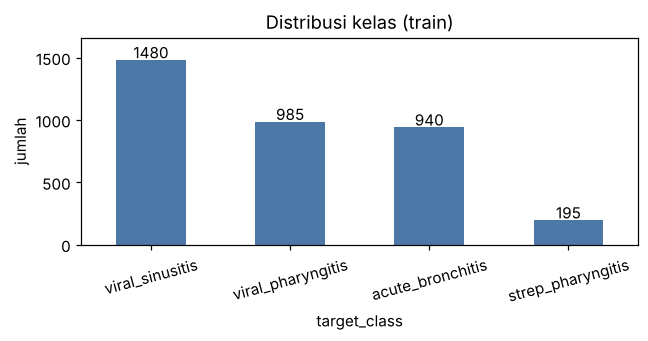

In [5]:
# ===== EDA 1: distribusi target =====
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

tr = feat[feat[TARGET].notna()].copy()          # train: target diketahui
te = feat[feat[TARGET].isna()].copy()           # test : target kosong
vc = tr[TARGET].value_counts()
print(pd.DataFrame({"jumlah": vc, "persen": (vc / len(tr) * 100).round(1)}))
print("rasio kelas terbanyak : tersedikit =", round(vc.max() / vc.min(), 1))

# pembanding bodoh: selalu menebak kelas terbanyak
tebak = np.full(len(tr), vc.index[0])
print(f"selalu tebak '{vc.index[0]}': akurasi {(tebak == tr[TARGET]).mean():.3f} tetapi macro-F1 hanya "
      f"{f1_score(tr[TARGET], tebak, average='macro'):.3f}")

ax = vc.plot.bar(color="#4C78A8", figsize=(6, 3.2), rot=15)
ax.set_title("Distribusi kelas (train)"); ax.set_ylabel("jumlah"); ax.set_ylim(0, vc.max() * 1.12)
for i, v in enumerate(vc.values): ax.text(i, v + 15, f"{v}", ha="center")
plt.tight_layout(); plt.show()

In [6]:
# ===== EDA 2: kualitas data mentah (kenapa kita membersihkan) =====
raw = patients
inc = raw["income_at_visit"].dropna().astype(str)
masalah = pd.Series({
    "umur = 999 (kode kosong)":            int((raw["age_at_visit"] == 999).sum()),
    "umur kosong":                         int(raw["age_at_visit"].isna().sum()),
    "income format campur ($, USD, k)":    int((~inc.str.fullmatch(r"\d+(\.\d+)?")).sum()),
    "income kosong":                       int(raw["income_at_visit"].isna().sum()),
    "status nikah ditulis penuh (Married..)": int((raw["marital_at_visit"].str.len() > 1).sum()),
    "status nikah kosong":                 int(raw["marital_at_visit"].isna().sum()),
    "ethnicity kosong":                    int(raw["ethnicity"].isna().sum()),
})
print(pd.DataFrame({"jumlah": masalah, "persen": (masalah / len(raw) * 100).round(1)}))
print("state unik:", raw["state"].nunique(), "| county unik:", raw["county"].nunique(), "| city unik:", raw["city"].nunique(),
      "-> state konstan, city/county terlalu banyak nilai untuk 3.600 baris (tidak dipakai)")

                                        jumlah  persen
umur = 999 (kode kosong)                    19     0.4
umur kosong                                 60     1.2
income format campur ($, USD, k)           690    13.8
income kosong                              455     9.1
status nikah ditulis penuh (Married..)     149     3.0
status nikah kosong                       1807    36.1
ethnicity kosong                           144     2.9
state unik: 1 | county unik: 58 | city unik: 520 -> state konstan, city/county terlalu banyak nilai untuk 3.600 baris (tidak dipakai)


    kolom     tipe  Cramer_V  p_value
   gender kategori     0.019    0.742
     race kategori     0.040    0.289
ethnicity kategori     0.037    0.139
  marital kategori     0.051    0.005
      age  numerik       NaN    0.001
   income  numerik       NaN    0.545
(6 uji sekaligus: p < 0,01 baru layak dilirik)

proporsi kelas per kelompok umur:
target_class  acute_bronchitis  strep_pharyngitis  viral_pharyngitis  viral_sinusitis
kel_umur                                                                             
<18                      0.280              0.099              0.264            0.357
18-40                    0.253              0.038              0.275            0.435
41-65                    0.254              0.042              0.291            0.413
>65                      0.265              0.052              0.243            0.440

umur median saat status nikah kosong vs terisi: 15.9 vs 51.0 | umur terendah yang status nikahnya terisi: 23.9


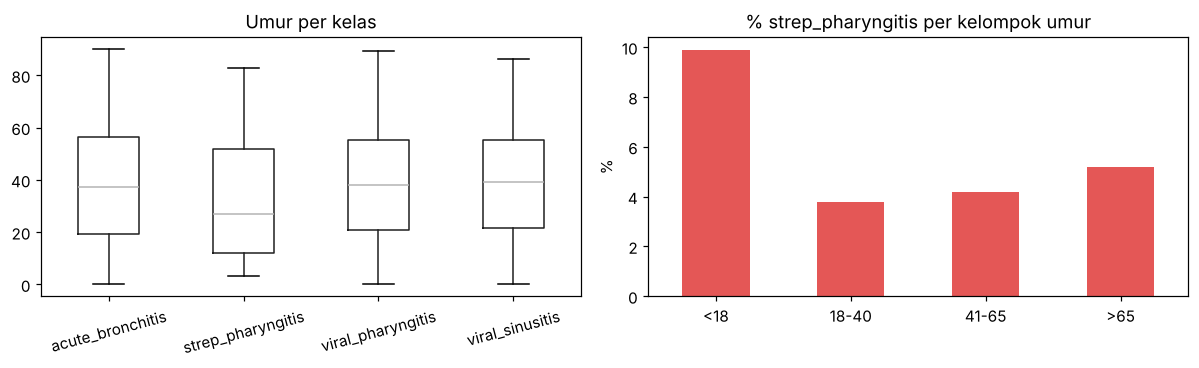

In [7]:
# ===== EDA 3: demografi vs kelas =====
from scipy.stats import chi2_contingency, kruskal

def cramers_v(a, b):
    """Kekuatan hubungan 2 kategori: 0 = tidak ada, 1 = sempurna."""
    ct = pd.crosstab(a, b)
    return np.sqrt(chi2_contingency(ct)[0] / (ct.values.sum() * (min(ct.shape) - 1)))

hasil = []
for c in ["gender", "race", "ethnicity", "marital"]:
    x = tr[c].astype(object).fillna("(kosong)")
    hasil.append((c, "kategori", cramers_v(x, tr[TARGET]), chi2_contingency(pd.crosstab(x, tr[TARGET]))[1]))
for c in ["age", "income"]:
    hasil.append((c, "numerik", np.nan, kruskal(*[d[c].dropna() for _, d in tr.groupby(TARGET)])[1]))
print(pd.DataFrame(hasil, columns=["kolom", "tipe", "Cramer_V", "p_value"]).round(3).to_string(index=False))
print("(6 uji sekaligus: p < 0,01 baru layak dilirik)")

# umur: strep paling muda? -> bandingkan proporsi kelas per kelompok umur
tr["kel_umur"] = pd.cut(tr["age"], [-0.1, 17.99, 40, 65, 120], labels=["<18", "18-40", "41-65", ">65"])
print("\nproporsi kelas per kelompok umur:")
print(pd.crosstab(tr["kel_umur"], tr[TARGET], normalize="index").round(3).to_string())

# status nikah kosong ternyata = anak-anak?
print("\numur median saat status nikah kosong vs terisi:",
      round(tr[tr.marital.isna()].age.median(), 1), "vs", round(tr[tr.marital.notna()].age.median(), 1),
      "| umur terendah yang status nikahnya terisi:", round(tr[tr.marital.notna()].age.min(), 1))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
tr.boxplot(column="age", by=TARGET, ax=ax[0], rot=15, grid=False); ax[0].set_title("Umur per kelas"); ax[0].set_xlabel(""); fig.suptitle("")
pd.crosstab(tr["kel_umur"], tr[TARGET], normalize="index")["strep_pharyngitis"].mul(100).plot.bar(ax=ax[1], color="#E45756", rot=0)
ax[1].set_title("% strep_pharyngitis per kelompok umur"); ax[1].set_xlabel(""); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

In [8]:
# ===== EDA 4: waktu kunjungan vs kelas (bandingkan dengan KEBETULAN) =====
tr["bulan"] = tr["prediction_time"].dt.month
tr["jam"]   = tr["prediction_time"].dt.hour
rng = np.random.RandomState(0)
for c in ["bulan", "jam"]:
    asli = cramers_v(tr[c], tr[TARGET])
    acak = [cramers_v(tr[c], rng.permutation(tr[TARGET].values)) for _ in range(200)]   # label diacak = tidak ada hubungan
    print(f"{c:6s}: Cramer V asli {asli:.3f} | label diacak rata-rata {np.mean(acak):.3f}, persentil-95 {np.percentile(acak, 95):.3f}"
          f" -> {'ada sinyal' if asli > np.percentile(acak, 95) else 'tidak beda dari kebetulan'}")
print("\nproporsi kelas per bulan:")
print(pd.crosstab(tr["bulan"], tr[TARGET], normalize="index").round(2).to_string())

bulan : Cramer V asli 0.055 | label diacak rata-rata 0.055, persentil-95 0.066 -> tidak beda dari kebetulan
jam   : Cramer V asli 0.086 | label diacak rata-rata 0.080, persentil-95 0.092 -> tidak beda dari kebetulan

proporsi kelas per bulan:
target_class  acute_bronchitis  strep_pharyngitis  viral_pharyngitis  viral_sinusitis
bulan                                                                                
1                         0.27               0.04               0.26             0.44
2                         0.24               0.03               0.32             0.41
3                         0.26               0.06               0.25             0.42
4                         0.26               0.07               0.26             0.40
5                         0.26               0.05               0.28             0.42
6                         0.27               0.06               0.28             0.38
7                         0.30               0.05               0.22 

In [9]:
# ===== EDA 5: apakah test mirip train? =====
from scipy.stats import ks_2samp
print("rentang waktu  train:", tr.prediction_time.min().date(), "->", tr.prediction_time.max().date())
print("rentang waktu  test :", te.prediction_time.min().date(), "->", te.prediction_time.max().date())
for c in ["age", "income"]:
    print(f"{c:6s} median train {tr[c].median():.1f} | test {te[c].median():.1f} | KS p = {ks_2samp(tr[c].dropna(), te[c].dropna())[1]:.3f}")
print("waktu  KS p =", round(ks_2samp(tr.prediction_time.astype('int64'), te.prediction_time.astype('int64'))[1], 3))
def hitung(d, c):
    return d[c].astype(object).fillna("(kosong)").value_counts()
for c in ["gender", "race", "marital"]:
    tabel = pd.concat([hitung(tr, c), hitung(te, c)], axis=1).fillna(0)       # baris = kategori, kolom = train/test
    print(f"{c:8s} p_value chi2 = {chi2_contingency(tabel)[1]:.3f}")
print("p besar (> 0,05) = tidak ada bukti train dan test berbeda")

rentang waktu  train: 2024-05-22 -> 2026-10-31
rentang waktu  test : 2024-03-27 -> 2026-10-29
age    median train 38.1 | test 39.0 | KS p = 0.451
income median train 68949.0 | test 68669.5 | KS p = 0.328
waktu  KS p = 0.406
gender   p_value chi2 = 0.524
race     p_value chi2 = 0.883
marital  p_value chi2 = 0.249
p besar (> 0,05) = tidak ada bukti train dan test berbeda


In [10]:
# ===== EDA 6: profil tabel triase & riwayat (rencana pembersihan berikutnya) =====
vitals   = pd.read_csv(TRI + "triage_vitals.csv")
symptoms = pd.read_csv(TRI + "triage_symptoms.csv")

print("-- satuan per tanda vital (jumlah baris) --")
print(pd.crosstab(vitals["vital_name"], vitals["unit"]).to_string())
v = pd.to_numeric(vitals["value"].astype(str).str.replace(",", ".", regex=False), errors="coerce")
print("\nnilai vital berkoma desimal:", int(vitals["value"].astype(str).str.contains(",").sum()),
      "| nilai > 500 (geser desimal):", int((v > 500).sum()))
print("varian nama gejala mentah:", symptoms["symptom_concept"].nunique(),
      "| setelah strip+lowercase:", symptoms["symptom_concept"].str.strip().str.lower().nunique())

cakupan = {}
for nama in ["previous_encounter", "conditions", "observations", "medications", "procedures", "immunizations", "allergies"]:
    d = pd.read_csv(HIS + f"{nama}.csv")
    cakupan[nama] = {"baris": len(d), "% pasien punya data": round(d[PASIEN].nunique() / len(base) * 100, 1)}
print("\n-- cakupan tabel riwayat --"); print(pd.DataFrame(cakupan).T.to_string())

-- satuan per tanda vital (jumlah baris) --
unit                 %  /min  beats/min  breaths/min  fraction  kPa  kg/m2  mmHg
vital_name                                                                      
BMI                  0     0          0            0         0    0   5000     0
Diastolic BP         0     0          0            0         0  317      0  4683
Heart rate           0  4333        667            0         0    0      0     0
Respiratory rate     0  4338          0          662         0    0      0     0
SpO2              4569     0          0            0       431    0      0     0
Systolic BP          0     0          0            0         0  301      0  4699

nilai vital berkoma desimal: 112 | nilai > 500 (geser desimal): 71
varian nama gejala mentah: 118 | setelah strip+lowercase: 70

-- cakupan tabel riwayat --
                      baris  % pasien punya data
previous_encounter   4471.0                 89.4
conditions           3583.0                 44.4
obs